# Data checks and example analytics

Run `create_tables.py` and `etl.py` first. Connection settings come from `.env` (see `.env.example`).

In [1]:
import pandas as pd
import psycopg2

import config

conn = psycopg2.connect(config.dsn())
conn.autocommit = True


def query(sql, params=None):
    """Run a SQL query and return the result as a DataFrame."""
    with conn.cursor() as cur:
        cur.execute(sql, params)
        cols = [c.name for c in cur.description]
        return pd.DataFrame(cur.fetchall(), columns=cols)

## Row counts

In [2]:
query('''
SELECT 'songplays' AS table_name, COUNT(*) AS rows FROM songplays
UNION ALL SELECT 'users',   COUNT(*) FROM users
UNION ALL SELECT 'songs',   COUNT(*) FROM songs
UNION ALL SELECT 'artists', COUNT(*) FROM artists
UNION ALL SELECT 'time',    COUNT(*) FROM time
''')

,table_name,rows
0,songplays,6820
1,users,96
2,songs,71
3,artists,69
4,time,6813


## Sample rows

In [3]:
for table in ['songplays', 'users', 'songs', 'artists', 'time']:
    print(table)
    display(query(f'SELECT * FROM {table} LIMIT 5'))

songplays


,songplay_id,start_time,user_id,level,song_id,artist_id,session_id,location,user_agent
0,1,2018-11-01 21:01:46.796,8,free,None,None,139,"Phoenix-Mesa-Scottsdale, AZ","""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK..."
1,2,2018-11-01 21:05:52.796,8,free,None,None,139,"Phoenix-Mesa-Scottsdale, AZ","""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK..."
2,3,2018-11-01 21:08:16.796,8,free,None,None,139,"Phoenix-Mesa-Scottsdale, AZ","""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK..."
3,4,2018-11-01 21:11:13.796,8,free,None,None,139,"Phoenix-Mesa-Scottsdale, AZ","""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK..."
4,5,2018-11-01 21:17:33.796,8,free,None,None,139,"Phoenix-Mesa-Scottsdale, AZ","""Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebK..."


users


,user_id,first_name,last_name,gender,level
0,62,Connar,Moreno,M,free
1,100,Adler,Barrera,M,free
2,69,Anabelle,Simpson,F,free
3,60,Devin,Larson,M,free
4,94,Noah,Chavez,M,free


songs


,song_id,title,artist_id,year,duration
0,SOMZWCG12A8C13C480,I Didn't Mean To,ARD7TVE1187B99BFB1,NaN,218.93179
1,SOCIWDW12A8C13D406,Soul Deep,ARMJAGH1187FB546F3,1969.0,148.03546
2,SOXVLOJ12AB0189215,Amor De Cabaret,ARKRRTF1187B9984DA,NaN,177.47546
3,SONHOTT12A8C13493C,Something Girls,AR7G5I41187FB4CE6C,1982.0,233.40363
4,SOFSOCN12A8C143F5D,Face the Ashes,ARXR32B1187FB57099,2007.0,209.60608


artists


,artist_id,name,location,latitude,longitude
0,ARD7TVE1187B99BFB1,Casual,California - LA,NaN,NaN
1,ARMJAGH1187FB546F3,The Box Tops,"Memphis, TN",35.14968,-90.04892
2,ARKRRTF1187B9984DA,Sonora Santanera,,NaN,NaN
3,AR7G5I41187FB4CE6C,Adam Ant,"London, England",NaN,NaN
4,ARXR32B1187FB57099,Gob,,NaN,NaN


time


,start_time,hour,day,week,month,year,weekday
0,2018-11-01 21:01:46.796,21,1,44,11,2018,3
1,2018-11-01 21:05:52.796,21,1,44,11,2018,3
2,2018-11-01 21:08:16.796,21,1,44,11,2018,3
3,2018-11-01 21:11:13.796,21,1,44,11,2018,3
4,2018-11-01 21:17:33.796,21,1,44,11,2018,3


## Quality checks

Each query should return 0.

In [4]:
checks = {
    'songplays with unknown time':   'SELECT COUNT(*) FROM songplays sp LEFT JOIN time t USING (start_time) WHERE t.start_time IS NULL',
    'songplays with unknown user':   'SELECT COUNT(*) FROM songplays sp LEFT JOIN users u USING (user_id) WHERE u.user_id IS NULL',
    'duplicate songplays':           'SELECT COUNT(*) - COUNT(DISTINCT (start_time, user_id, session_id)) FROM songplays',
    'timestamps outside 2018':       'SELECT COUNT(*) FROM time WHERE year <> 2018',
}
pd.DataFrame(
    [(name, query(sql).iloc[0, 0]) for name, sql in checks.items()],
    columns=['check', 'failures'],
)

,check,failures
0,songplays with unknown time,0
1,songplays with unknown user,0
2,duplicate songplays,0
3,timestamps outside 2018,0


## Example analytics

### Busiest hours of the day

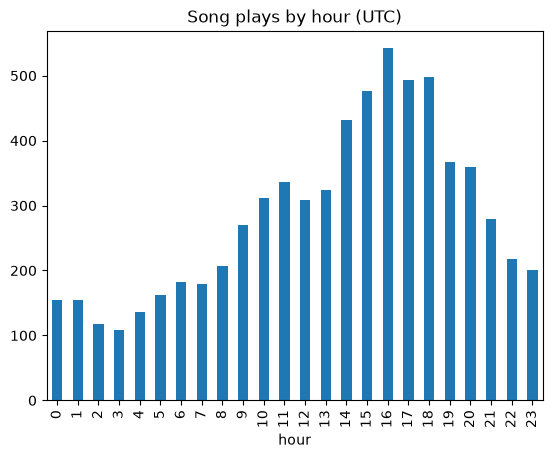

In [5]:
query('''
SELECT t.hour, COUNT(*) AS plays
FROM songplays sp
JOIN time t USING (start_time)
GROUP BY t.hour
ORDER BY t.hour
''').set_index('hour').plot.bar(title='Song plays by hour (UTC)', legend=False);

### Free vs paid listening

In [6]:
query('''
SELECT level, COUNT(*) AS plays, COUNT(DISTINCT user_id) AS users
FROM songplays
GROUP BY level
''')

,level,plays,users
0,free,1229,82
1,paid,5591,22


### Most active users

In [7]:
query('''
SELECT u.user_id, u.first_name, u.last_name, u.level, COUNT(*) AS plays
FROM songplays sp
JOIN users u USING (user_id)
GROUP BY u.user_id, u.first_name, u.last_name, u.level
ORDER BY plays DESC
LIMIT 10
''')

,user_id,first_name,last_name,level,plays
0,49,Chloe,Cuevas,paid,689
1,80,Tegan,Levine,paid,665
2,97,Kate,Harrell,paid,557
3,15,Lily,Koch,paid,463
4,44,Aleena,Kirby,paid,397
5,29,Jacqueline,Lynch,paid,346
6,24,Layla,Griffin,paid,321
7,73,Jacob,Klein,paid,289
8,88,Mohammad,Rodriguez,paid,270
9,36,Matthew,Jones,paid,248


In [8]:
conn.close()